# Experiment 9: Text Preprocessing and Feature Scaling Using Python

**Aim:** To perform text preprocessing, feature extraction, normalization, and feature scaling techniques for machine learning applications using Python.

**Mapped CO(s):** CO2


## 1. Import Required Libraries


In [1]:
import re

import matplotlib.pyplot as plt
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler, StandardScaler

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 80)
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()
print("Libraries imported")
print("English stop words loaded:", len(STOP_WORDS))


Libraries imported
English stop words loaded: 198


## 2. Load the Text Dataset

A small set of sentences is used so each preprocessing step can be checked by hand.


In [2]:
texts = [
    "Machine learning models need clean and consistent text data.",
    "Text preprocessing removes punctuation, stop words, and special characters!",
    "Stemming and lemmatization normalize words before feature extraction.",
    "TF-IDF converts documents into numerical feature vectors.",
    "Feature scaling uses normalization and standardization for machine learning.",
]
df = pd.DataFrame({"Text": texts})
print("Dataset loaded successfully")
print("Shape:", df.shape)
df


Dataset loaded successfully
Shape: (5, 1)


,Text
0,Machine learning models need clean and consistent text data.
1,"Text preprocessing removes punctuation, stop words, and special characters!"
2,Stemming and lemmatization normalize words before feature extraction.
3,TF-IDF converts documents into numerical feature vectors.
4,Feature scaling uses normalization and standardization for machine learning.


## 3. Text Preprocessing

Steps applied to every sentence:

1. Convert to lowercase.
2. Remove punctuation and special characters.
3. Tokenize on whitespace.
4. Remove stop words.
5. Stem the remaining tokens (Porter stemmer).


In [3]:
def tokenize(text):
    cleaned = re.sub(r"[^a-z\s]", " ", text.lower())
    return [token for token in cleaned.split() if token]


def normalize_tokens(tokens, method):
    if method == "stem":
        return [STEMMER.stem(token) for token in tokens]
    lemmas = []
    for token in tokens:
        verb = LEMMATIZER.lemmatize(token, pos="v")
        lemmas.append(LEMMATIZER.lemmatize(verb, pos="n"))
    return lemmas


def preprocess(text, method="stem"):
    tokens = [token for token in tokenize(text) if token not in STOP_WORDS]
    return normalize_tokens(tokens, method)


df["Tokens"] = df["Text"].apply(tokenize)
df["Without stop words"] = df["Tokens"].apply(lambda tokens: [t for t in tokens if t not in STOP_WORDS])
df["Stemmed"] = df["Without stop words"].apply(lambda tokens: normalize_tokens(tokens, "stem"))
df["Processed text"] = df["Stemmed"].apply(lambda tokens: " ".join(tokens))

print("Stop words removed and tokens stemmed")
df[["Text", "Without stop words", "Stemmed"]]


Stop words removed and tokens stemmed


,Text,Without stop words,Stemmed
0,Machine learning models need clean and consistent text data.,"[machine, learning, models, need, clean, consistent, text, data]","[machin, learn, model, need, clean, consist, text, data]"
1,"Text preprocessing removes punctuation, stop words, and special characters!","[text, preprocessing, removes, punctuation, stop, words, special, characters]","[text, preprocess, remov, punctuat, stop, word, special, charact]"
2,Stemming and lemmatization normalize words before feature extraction.,"[stemming, lemmatization, normalize, words, feature, extraction]","[stem, lemmat, normal, word, featur, extract]"
3,TF-IDF converts documents into numerical feature vectors.,"[tf, idf, converts, documents, numerical, feature, vectors]","[tf, idf, convert, document, numer, featur, vector]"
4,Feature scaling uses normalization and standardization for machine learning.,"[feature, scaling, uses, normalization, standardization, machine, learning]","[featur, scale, use, normal, standard, machin, learn]"


## 4. TF-IDF Feature Extraction

TF-IDF turns each processed sentence into a numerical vector. A word that appears in many sentences gets a lower weight than a word that is concentrated in a few sentences.


In [4]:
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(df["Processed text"])
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray().round(3),
    columns=tfidf.get_feature_names_out(),
    index=[f"Doc {i + 1}" for i in range(len(df))],
)
print("TF-IDF feature matrix generated")
print("Shape (documents, features):", tfidf_df.shape)
tfidf_df


TF-IDF feature matrix generated
Shape (documents, features): (5, 29)


,charact,clean,consist,convert,data,document,extract,featur,idf,learn,...,scale,special,standard,stem,stop,text,tf,use,vector,word
Doc 1,0.00,0.379,0.379,0.000,0.379,0.000,0.000,0.000,0.000,0.306,...,0.00,0.00,0.00,0.000,0.00,0.306,0.000,0.00,0.000,0.000
Doc 2,0.37,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.00,0.37,0.00,0.000,0.37,0.299,0.000,0.00,0.000,0.299
Doc 3,0.00,0.000,0.000,0.000,0.000,0.000,0.459,0.307,0.000,0.000,...,0.00,0.00,0.00,0.459,0.00,0.000,0.000,0.00,0.000,0.370
Doc 4,0.00,0.000,0.000,0.394,0.000,0.394,0.000,0.264,0.394,0.000,...,0.00,0.00,0.00,0.000,0.00,0.000,0.394,0.00,0.394,0.000
Doc 5,0.00,0.000,0.000,0.000,0.000,0.000,0.000,0.288,0.000,0.347,...,0.43,0.00,0.43,0.000,0.00,0.000,0.000,0.43,0.000,0.000


## 5. Normalize and Standardize the TF-IDF Features

- **Normalization (Min-Max):** scales each feature to the range 0 to 1.
- **Standardization (Z-score):** shifts each feature to mean 0 and standard deviation 1.


In [5]:
minmax = MinMaxScaler()
standard = StandardScaler()
tfidf_minmax = pd.DataFrame(
    minmax.fit_transform(tfidf_df).round(3),
    columns=tfidf_df.columns,
    index=tfidf_df.index,
)
tfidf_standard = pd.DataFrame(
    standard.fit_transform(tfidf_df).round(3),
    columns=tfidf_df.columns,
    index=tfidf_df.index,
)
print("Min-Max scaled TF-IDF (values between 0 and 1)")
display(tfidf_minmax)
print("Standardized TF-IDF (mean about 0)")
display(tfidf_standard)
print("Min-Max range:", float(tfidf_minmax.min().min()), "to", float(tfidf_minmax.max().max()))
print("Standardized means (first 5 features):")
print(tfidf_standard.mean().round(3).head())


Min-Max scaled TF-IDF (values between 0 and 1)


,charact,clean,consist,convert,data,document,extract,featur,idf,learn,...,scale,special,standard,stem,stop,text,tf,use,vector,word
Doc 1,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.000,0.0,0.882,...,0.0,0.0,0.0,0.0,0.0,1.000,0.0,0.0,0.0,0.000
Doc 2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.000,...,0.0,1.0,0.0,0.0,1.0,0.977,0.0,0.0,0.0,0.808
Doc 3,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.000,0.0,0.000,...,0.0,0.0,0.0,1.0,0.0,0.000,0.0,0.0,0.0,1.000
Doc 4,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.860,1.0,0.000,...,0.0,0.0,0.0,0.0,0.0,0.000,1.0,0.0,1.0,0.000
Doc 5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.938,0.0,1.000,...,1.0,0.0,1.0,0.0,0.0,0.000,0.0,1.0,0.0,0.000


Standardized TF-IDF (mean about 0)


,charact,clean,consist,convert,data,document,extract,featur,idf,learn,...,scale,special,standard,stem,stop,text,tf,use,vector,word
Doc 1,-0.5,2.0,2.0,-0.5,2.0,-0.5,-0.5,-1.219,-0.5,1.093,...,-0.5,-0.5,-0.5,-0.5,-0.5,1.248,-0.5,-0.5,-0.5,-0.809
Doc 2,2.0,-0.5,-0.5,-0.5,-0.5,-0.5,-0.5,-1.219,-0.5,-0.814,...,-0.5,2.0,-0.5,-0.5,2.0,1.201,-0.5,-0.5,-0.5,0.999
Doc 3,-0.5,-0.5,-0.5,-0.5,-0.5,-0.5,2.0,0.959,-0.5,-0.814,...,-0.5,-0.5,-0.5,2.0,-0.5,-0.816,-0.5,-0.5,-0.5,1.428
Doc 4,-0.5,-0.5,-0.5,2.0,-0.5,2.0,-0.5,0.654,2.0,-0.814,...,-0.5,-0.5,-0.5,-0.5,-0.5,-0.816,2.0,-0.5,2.0,-0.809
Doc 5,-0.5,-0.5,-0.5,-0.5,-0.5,-0.5,-0.5,0.824,-0.5,1.348,...,2.0,-0.5,2.0,-0.5,-0.5,-0.816,-0.5,2.0,-0.5,-0.809


Min-Max range: 0.0 to 1.0
Standardized means (first 5 features):
charact    0.0
clean      0.0
consist    0.0
convert    0.0
data       0.0
dtype: float64


---
## Exercises / Assignments


### Exercise 1: Apply CountVectorizer to the same text dataset


In [6]:
count_vectorizer = CountVectorizer()
count_matrix = count_vectorizer.fit_transform(df["Processed text"])
count_df = pd.DataFrame(
    count_matrix.toarray(),
    columns=count_vectorizer.get_feature_names_out(),
    index=tfidf_df.index,
)
print("CountVectorizer matrix (raw word counts)")
count_df


CountVectorizer matrix (raw word counts)


,charact,clean,consist,convert,data,document,extract,featur,idf,learn,...,scale,special,standard,stem,stop,text,tf,use,vector,word
Doc 1,0,1,1,0,1,0,0,0,0,1,...,0,0,0,0,0,1,0,0,0,0
Doc 2,1,0,0,0,0,0,0,0,0,0,...,0,1,0,0,1,1,0,0,0,1
Doc 3,0,0,0,0,0,0,1,1,0,0,...,0,0,0,1,0,0,0,0,0,1
Doc 4,0,0,0,1,0,1,0,1,1,0,...,0,0,0,0,0,0,1,0,1,0
Doc 5,0,0,0,0,0,0,0,1,0,1,...,1,0,1,0,0,0,0,1,0,0


### Exercise 2: Compare TF-IDF and CountVectorizer outputs


In [7]:
shared_terms = ["learn", "data", "featur", "text", "normal"]
comparison = pd.DataFrame({
    "Count (Doc 1)": count_df.loc["Doc 1", shared_terms].values,
    "TF-IDF (Doc 1)": tfidf_df.loc["Doc 1", shared_terms].values,
    "Count (Doc 5)": count_df.loc["Doc 5", shared_terms].values,
    "TF-IDF (Doc 5)": tfidf_df.loc["Doc 5", shared_terms].values,
}, index=shared_terms)
print("CountVectorizer stores how often a word appears.")
print("TF-IDF down-weights words that appear in many documents, such as 'learn' and 'featur'.")
comparison


CountVectorizer stores how often a word appears.
TF-IDF down-weights words that appear in many documents, such as 'learn' and 'featur'.


,Count (Doc 1),TF-IDF (Doc 1),Count (Doc 5),TF-IDF (Doc 5)
learn,1,0.306,1,0.347
data,1,0.379,0,0.000
featur,0,0.000,1,0.288
text,1,0.306,0,0.000
normal,0,0.000,1,0.347


### Exercise 3: Perform lemmatization instead of stemming


In [8]:
sample_words = ["learning", "models", "removes", "characters", "normalize", "documents", "uses", "scaling"]
lemma_vs_stem = pd.DataFrame({
    "Word": sample_words,
    "Stem": [STEMMER.stem(word) for word in sample_words],
    "Lemma": [LEMMATIZER.lemmatize(LEMMATIZER.lemmatize(word, pos="v"), pos="n") for word in sample_words],
})
df["Lemmatized"] = df["Without stop words"].apply(lambda tokens: normalize_tokens(tokens, "lemma"))
print("Stemming chops words. Lemmatization returns a dictionary form.")
display(lemma_vs_stem)
print("Same sentences after lemmatization:")
df[["Stemmed", "Lemmatized"]]


Stemming chops words. Lemmatization returns a dictionary form.


,Word,Stem,Lemma
0,learning,learn,learn
1,models,model,model
2,removes,remov,remove
3,characters,charact,character
4,normalize,normal,normalize
5,documents,document,document
6,uses,use,use
7,scaling,scale,scale


Same sentences after lemmatization:


,Stemmed,Lemmatized
0,"[machin, learn, model, need, clean, consist, text, data]","[machine, learn, model, need, clean, consistent, text, data]"
1,"[text, preprocess, remov, punctuat, stop, word, special, charact]","[text, preprocessing, remove, punctuation, stop, word, special, character]"
2,"[stem, lemmat, normal, word, featur, extract]","[stem, lemmatization, normalize, word, feature, extraction]"
3,"[tf, idf, convert, document, numer, featur, vector]","[tf, idf, convert, document, numerical, feature, vector]"
4,"[featur, scale, use, normal, standard, machin, learn]","[feature, scale, use, normalization, standardization, machine, learn]"


### Exercise 4: Apply Min-Max Scaling to another numerical dataset

Income is in the tens of thousands, while Age and Score are small numbers. Min-Max scaling puts every column on the same 0 to 1 range.


In [9]:
numbers = pd.DataFrame({
    "Age": [18, 22, 35, 45, 60],
    "Income": [20000, 35000, 80000, 120000, 90000],
    "Score": [55, 70, 88, 92, 61],
})
numbers_minmax = pd.DataFrame(
    MinMaxScaler().fit_transform(numbers).round(3),
    columns=numbers.columns,
)
print("Original numerical dataset")
display(numbers)
print("After Min-Max scaling")
numbers_minmax


Original numerical dataset


,Age,Income,Score
0,18,20000,55
1,22,35000,70
2,35,80000,88
3,45,120000,92
4,60,90000,61


After Min-Max scaling


,Age,Income,Score
0,0.000,0.00,0.000
1,0.095,0.15,0.405
2,0.405,0.60,0.892
3,0.643,1.00,1.000
4,1.000,0.70,0.162


### Exercise 5: Compare Normalization and Standardization results


Min-Max keeps every value between 0 and 1. Standardization centers each column at 0.


Original               Min-Max               Standardized              
       Age  Income Score     Age Income  Score          Age Income  Score
0       18   20000    55   0.000   0.00  0.000       -1.173 -1.337 -1.248
1       22   35000    70   0.095   0.15  0.405       -0.912 -0.927 -0.219
2       35   80000    88   0.405   0.60  0.892       -0.065  0.300  1.015
3       45  120000    92   0.643   1.00  1.000        0.586  1.391  1.289
4       60   90000    61   1.000   0.70  0.162        1.564  0.573 -0.837

Column minimums and maximums
        Min-Max min  Min-Max max  Standard mean  Standard std
Age             0.0          1.0            0.0           1.0
Income          0.0          1.0           -0.0           1.0
Score           0.0          1.0           -0.0           1.0


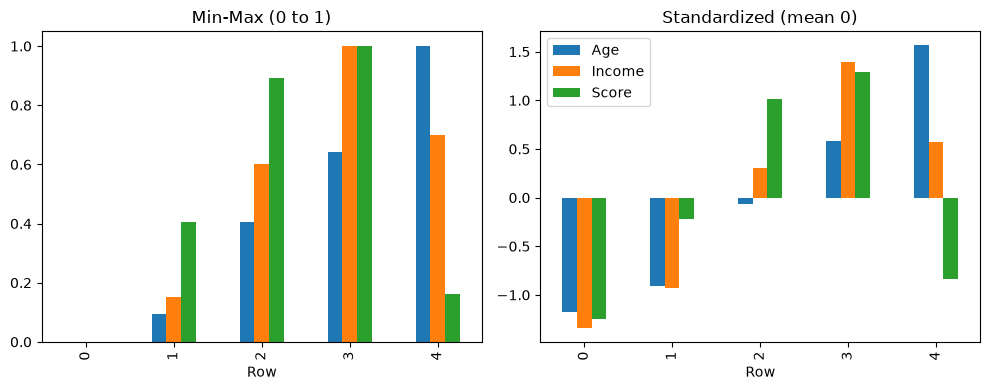

In [10]:
numbers_standard = pd.DataFrame(
    StandardScaler().fit_transform(numbers).round(3),
    columns=numbers.columns,
)
scaled_compare = pd.concat(
    {"Original": numbers, "Min-Max": numbers_minmax, "Standardized": numbers_standard},
    axis=1,
)
print("Min-Max keeps every value between 0 and 1. Standardization centers each column at 0.")
display(scaled_compare.round(3))
print("Column minimums and maximums")
print(pd.DataFrame({
    "Min-Max min": numbers_minmax.min(),
    "Min-Max max": numbers_minmax.max(),
    "Standard mean": numbers_standard.mean().round(3),
    "Standard std": numbers_standard.std(ddof=0).round(3),
}))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
numbers_minmax.plot(kind="bar", ax=axes[0], legend=False)
axes[0].set_title("Min-Max (0 to 1)")
axes[0].set_xlabel("Row")
numbers_standard.plot(kind="bar", ax=axes[1])
axes[1].set_title("Standardized (mean 0)")
axes[1].set_xlabel("Row")
axes[1].legend(loc="upper left")
fig.tight_layout()
plt.show()


---
## Observation

- The five sentences were loaded and cleaned.
- Punctuation and stop words were removed, and the remaining words were stemmed.
- TF-IDF produced a numerical feature matrix.
- Min-Max scaling mapped those features to the range 0 to 1, and standardization centered them at mean 0.
- CountVectorizer kept raw counts. Lemmatization kept readable word forms where stemming chopped them.

## Result

Text preprocessing, TF-IDF feature extraction, normalization, and standardization were completed. The scaled numerical features are ready to be used by a machine learning model.

## Conclusion

Raw text is a poor input for most machine learning models. Cleaning, TF-IDF, and feature scaling turn that text into numbers on a comparable scale. Normalization is useful when a fixed 0 to 1 range is needed. Standardization is useful when features should share a mean of 0 and a standard deviation of 1.
